<a href="https://colab.research.google.com/github/justleein2/MachineLearning/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task 1:

400
4096
(400, 64, 64)
40


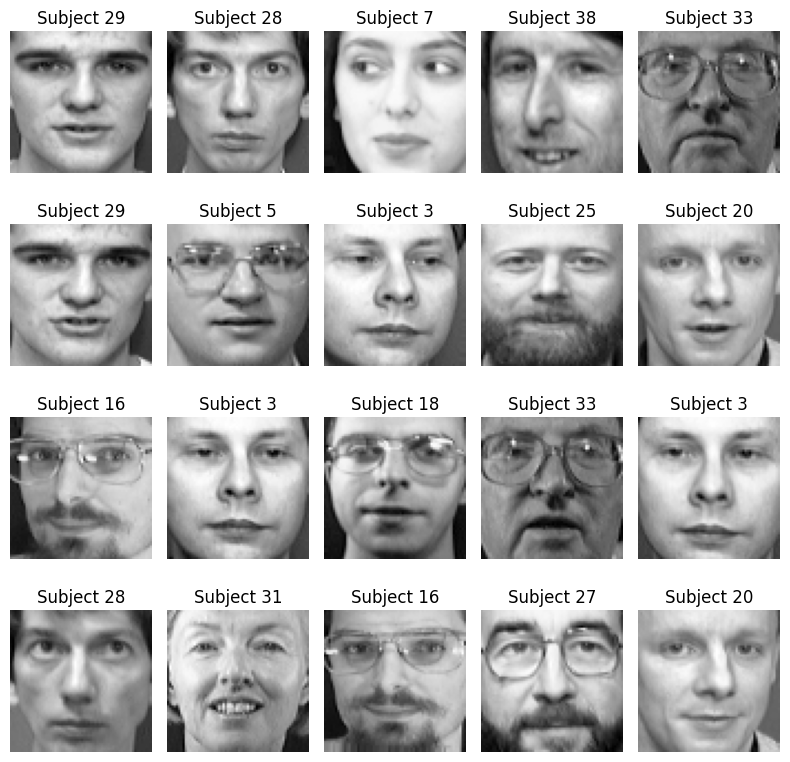

In [52]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces

faces = fetch_olivetti_faces()
X = faces.data
images = faces.images
y = faces.target

print(X.shape[0])
print(X.shape[1])
print(images.shape)
print(len(np.unique(y)))

rng = np.random.default_rng(42)
idx = rng.choice(len(X), 20, replace=False)

fig, axes = plt.subplots(4, 5, figsize=(8, 8))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Subject {y[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

Task 2:

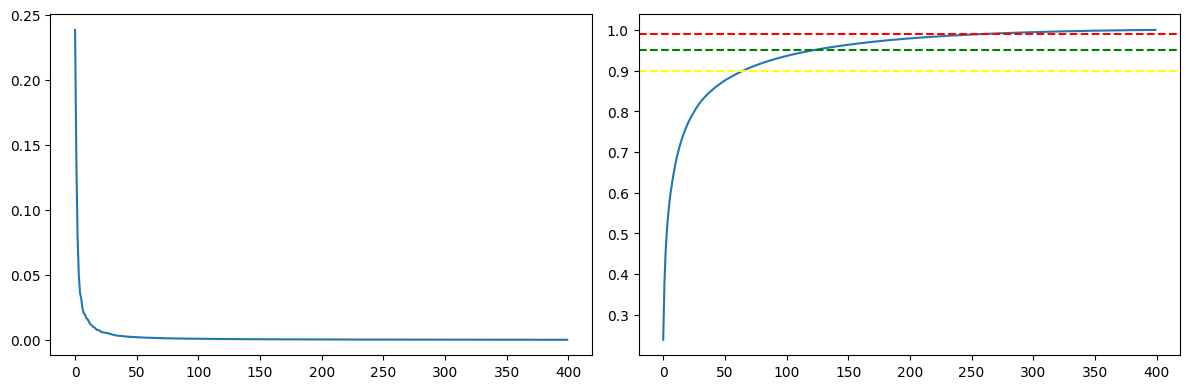

90% variance needs 66 components
95% variance needs 123 components
99% variance needs 260 components


In [53]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X)
cum_var = np.cumsum(pca.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(pca.explained_variance_ratio_)
axes[1].plot(cum_var)
axes[1].axhline(0.90, color="yellow", ls="--", label="90%")
axes[1].axhline(0.95, color="green",  ls="--", label="95%")
axes[1].axhline(0.99, color="red",    ls="--", label="99%")
plt.tight_layout()
plt.show()

for t in [0.90, 0.95, 0.99]:
    k = np.argmax(cum_var >= t) + 1
    print(f"{int(t*100)}% variance needs {k} components")

Task 3:

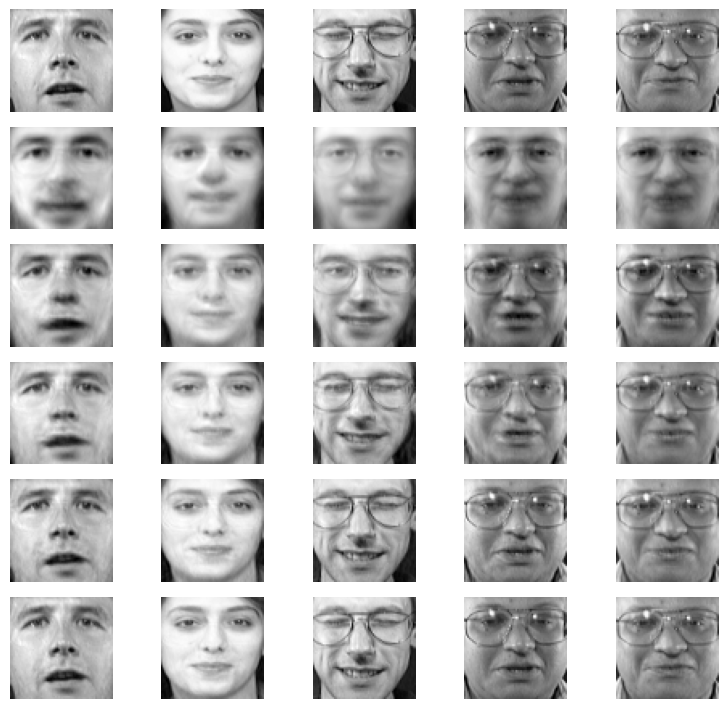

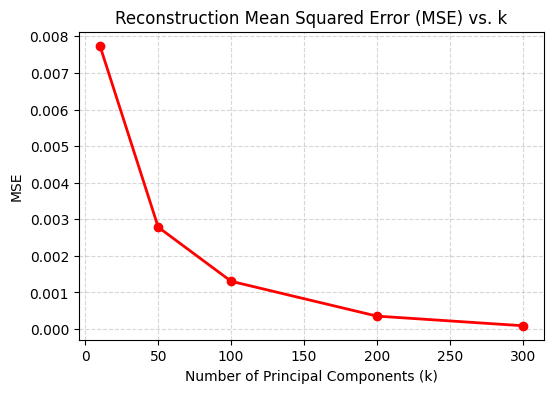

In [61]:
ks = [10, 50, 100, 200, 300]
idx = rng.choice(400, 5, replace=False)


fig, axes = plt.subplots(len(ks) + 1, 5, figsize=(8, 1.2 * (len(ks) + 1)))

# Plot original images in the first row (row 0)
for j in range(5):
    axes[0, j].imshow(images[idx[j]], cmap="gray")
    axes[0, j].axis("off")
axes[0, 0].set_ylabel("Original", rotation=0, labelpad=30, fontsize=9, fontweight='bold')

mses = []
for row, k in enumerate(ks, start=1):
    p = PCA(n_components=k)
    p.fit(X)
    recon = p.inverse_transform(p.transform(X[idx])).reshape(-1, 64, 64)

    mse = np.mean((X[idx] - recon.reshape(5, -1)) ** 2)
    mses.append(mse)

    for j in range(5):
        axes[row, j].imshow(recon[j], cmap="gray")
        axes[row, j].axis("off")
    axes[row, 0].set_ylabel(f"k={k}", rotation=0, labelpad=30, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(ks, mses, "o-", color="red", linewidth=2)
plt.title("Reconstruction Mean Squared Error (MSE) vs. k", fontsize=12)
plt.xlabel("Number of Principal Components (k)", fontsize=10)
plt.ylabel("MSE", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Task 4:

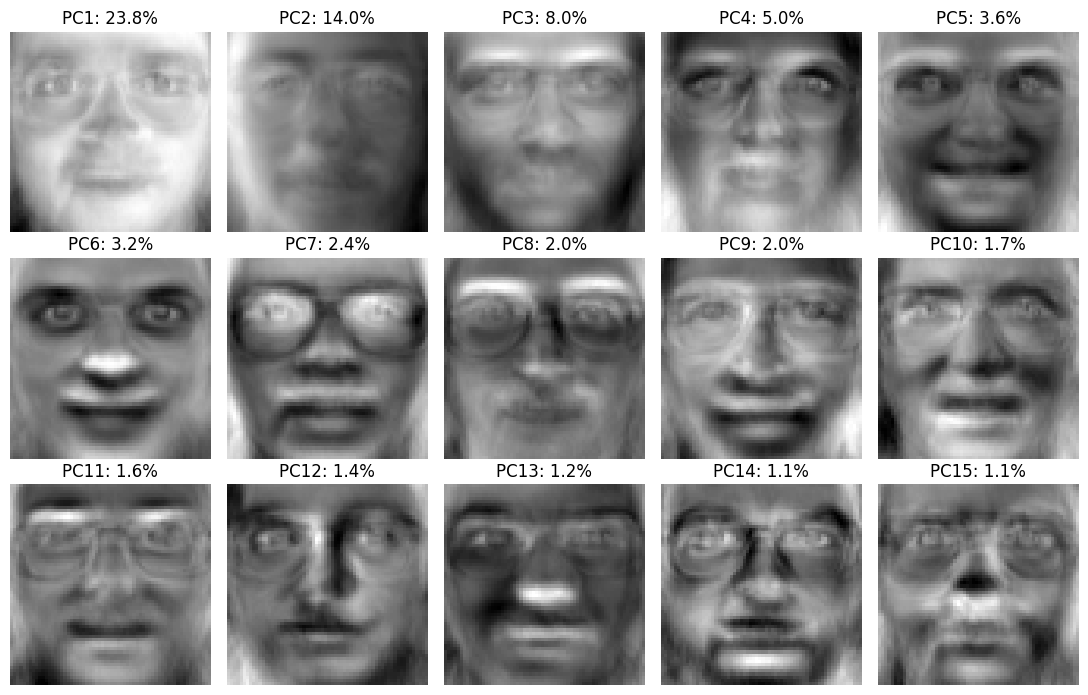

In [55]:
fig, axes = plt.subplots(3, 5, figsize=(11, 7))

for i, ax in enumerate(axes.ravel()):
    ef = pca.components_[i].reshape(64, 64)
    ax.imshow(ef, cmap="gray")
    ax.set_title(f"PC{i+1}: {pca.explained_variance_ratio_[i]*100:.1f}%")
    ax.axis("off")

plt.tight_layout()
plt.show()

Task 5:

In [56]:
import time

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

t0 = time.time()
lr_raw = LogisticRegression(max_iter=2000)
lr_raw.fit(X_train, y_train)
raw_time = time.time() - t0
raw_acc = lr_raw.score(X_test, y_test)

pca95 = PCA(n_components=0.95, random_state=42)
X_train_pca = pca95.fit_transform(X_train)
X_test_pca  = pca95.transform(X_test)
print("PCA kept", pca95.n_components_, "components")

t0 = time.time()
lr_pca = LogisticRegression(max_iter=2000)
lr_pca.fit(X_train_pca, y_train)
pca_time = time.time() - t0
pca_acc = lr_pca.score(X_test_pca, y_test)

print(f"Raw:  acc={raw_acc:.3f}  time={raw_time:.3f}s")
print(f"PCA:  acc={pca_acc:.3f}  time={pca_time:.3f}s")

PCA kept 111 components
Raw:  acc=0.963  time=24.098s
PCA:  acc=0.963  time=0.263s


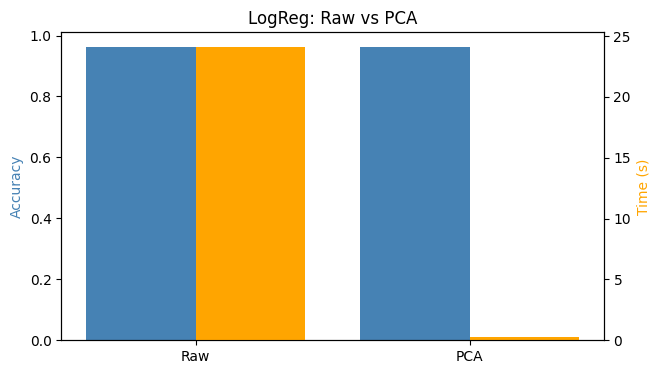

In [57]:
labels = ["Raw", "PCA"]
x = np.arange(2)
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.bar(x - 0.2, [raw_acc, pca_acc], 0.4, color="steelblue", label="Accuracy")
ax1.set_ylabel("Accuracy", color="steelblue")
ax1.set_xticks(x); ax1.set_xticklabels(labels)

ax2 = ax1.twinx()
ax2.bar(x + 0.2, [raw_time, pca_time], 0.4, color="orange", label="Time")
ax2.set_ylabel("Time (s)", color="orange")
plt.title("LogReg: Raw vs PCA")
plt.show()

Task 6:

SVC RBF: acc=0.975  time=0.035s


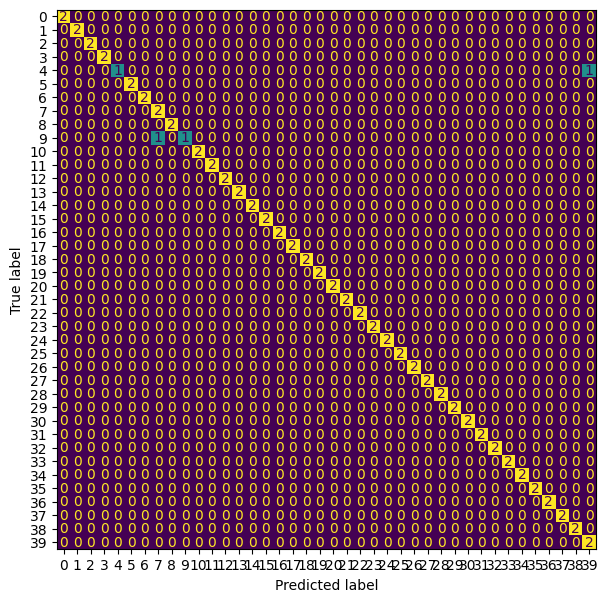

In [58]:
from sklearn.svm import SVC

t0 = time.time()
svc = SVC(kernel="rbf", C=10)
svc.fit(X_train_pca, y_train)
svc_time = time.time() - t0

y_pred_svc = svc.predict(X_test_pca)
svc_acc = accuracy_score(y_test, y_pred_svc)

print(f"SVC RBF: acc={svc_acc:.3f}  time={svc_time:.3f}s")

cm = confusion_matrix(y_test, y_pred_svc)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm).plot(ax=ax, colorbar=False)
plt.show()

Task 7:

In [59]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import VotingClassifier


ens = VotingClassifier(
    estimators=[
        ("poly", SVC(kernel="poly", degree=2, C=10, probability=True)),
        ("rbf",  SVC(kernel="rbf", C=10, probability=True)),
        ("rf",   RandomForestClassifier(n_estimators=100, random_state=42)),
    ],
    voting="soft"
)

t0 = time.time()
ens.fit(X_train_pca, y_train)
ens_time = time.time() - t0
ens_acc = ens.score(X_test_pca, y_test)

print(f"Ensemble: acc={ens_acc:.3f}  time={ens_time:.3f}s")

Ensemble: acc=0.975  time=0.974s


Task 8:

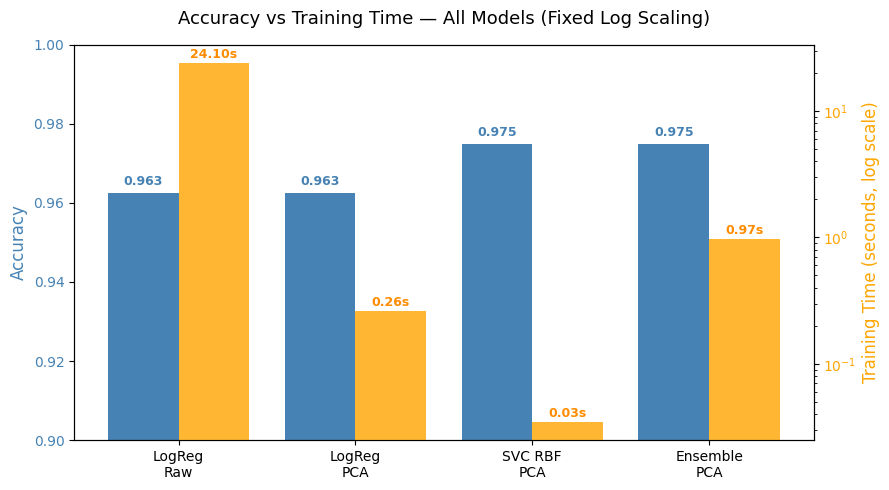

In [60]:
names = ["LogReg\nRaw", "LogReg\nPCA", "SVC RBF\nPCA", "Ensemble\nPCA"]
accs  = [raw_acc, pca_acc, svc_acc, ens_acc]
times = [raw_time, pca_time, svc_time, ens_time]

x = np.arange(4)
fig, ax1 = plt.subplots(figsize=(9, 5))

# Left Axis - Accuracy (Linear Scale)
ax1.bar(x - 0.2, accs, 0.4, color="steelblue", label="Accuracy")
ax1.set_ylabel("Accuracy", color="steelblue", fontsize=12)
ax1.set_ylim(0.9, 1.0)  # Zoom in on accuracies to show variations
ax1.set_xticks(x)
ax1.set_xticklabels(names, fontsize=10)
ax1.tick_params(axis='y', labelcolor="steelblue")
for xi, a in zip(x, accs):
    ax1.text(xi - 0.2, a + 0.002, f"{a:.3f}", ha="center", fontsize=9, fontweight='bold', color="steelblue")

# Right Axis - Training Time (Logarithmic Scale to fix scaling discrepancy)
ax2 = ax1.twinx()
ax2.bar(x + 0.2, times, 0.4, color="orange", label="Time", alpha=0.8)
ax2.set_yscale("log")
ax2.set_ylabel("Training Time (seconds, log scale)", color="orange", fontsize=12)
ax2.tick_params(axis='y', labelcolor="orange")
for xi, t in zip(x, times):
    ax2.text(xi + 0.2, t * 1.1, f"{t:.2f}s", ha="center", fontsize=9, fontweight='bold', color="darkorange")

plt.title("Accuracy vs Training Time — All Models (Fixed Log Scaling)", fontsize=13, pad=15)
plt.tight_layout()
plt.show()